In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import math
from typing import Optional

import numpy as np
import math
import matplotlib.pyplot as plt
from dataclasses import dataclass

params = {
"legend.fontsize": 15,
#   'figure.figsize': (8, 5),
"axes.labelsize": 18,  # 'x-large',
"axes.titlesize": 20,  # 'x-large',
"xtick.labelsize": 16,
"ytick.labelsize": 18,
"pdf.fonttype": 42,
"ps.fonttype": 42,
}
plt.rcParams.update(params)


In [3]:

def surface_code_p_mem(p_phy: float, d: int, A: float = 0.03, p_th: float = 0.01) -> float:
    """
    Fowler-style below-threshold ansatz:
        p_mem ≈ A * (p_phy / p_th) ** de
    where de = floor((d+1)/2).
    """
    if p_phy <= 0 or p_th <= 0 or A <= 0:
        raise ValueError("p_phy, p_th, and A must be positive.")
    if d < 1:
        raise ValueError("d must be >= 1.")
    de = (d + 1) // 2  # floor((d+1)/2)
    return A * (p_phy / p_th) ** de


def surface_dist_for_trgt_p_mem(
    p_phy: float,
    p_target: float,
    A: float = 0.03,
    p_th: float = 0.01,
    min_d: int = 3,
) -> int:
    """
    Returns the smallest (typically odd) distance d such that
        surface_code_p_mem(p_phy, d) <= p_target
    under the Fowler-style ansatz.

    Notes:
    - Valid only in the below-threshold regime p_phy < p_th.
    - Because de=floor((d+1)/2), increasing d by 1 (even->odd) sometimes doesn't help;
      the minimal solution is always odd in this model.
    """
    if p_target <= 0:
        raise ValueError("p_target must be positive.")
    if p_phy <= 0 or p_th <= 0 or A <= 0:
        raise ValueError("p_phy, p_th, and A must be positive.")
    if p_phy >= p_th:
        raise ValueError("This below-threshold inversion assumes p_phy < p_th.")

    # If already satisfied at min_d, return min_d
    if surface_code_p_mem(p_phy, min_d, A=A, p_th=p_th) <= p_target:
        return min_d

    r = p_phy / p_th  # in (0,1)
    # Solve A * r^de = p_target  =>  de = log(p_target/A) / log(r)
    de_real = math.log(p_target / A) / math.log(r)

    # Need integer de such that A*r^de <= p_target; since r<1, this means de >= de_real
    de_needed = math.ceil(de_real)

    # Smallest d with floor((d+1)/2) >= de_needed is d = 2*de_needed - 1 (odd)
    d = 2 * de_needed - 1
    return max(min_d, d)

def physical_qubits_for_surf_dist(d: int) -> int:
    return 2 * d * d


@dataclass(frozen=True)
class Protocol:
    name: str # unique name
    c: float
    t: float

    def p_out(self, p_in: float) -> float:
        return self.c * p_in**self.t
    
    def p_in(self, p_out: float) -> float:
        return (p_out / self.c)**(1/self.t)



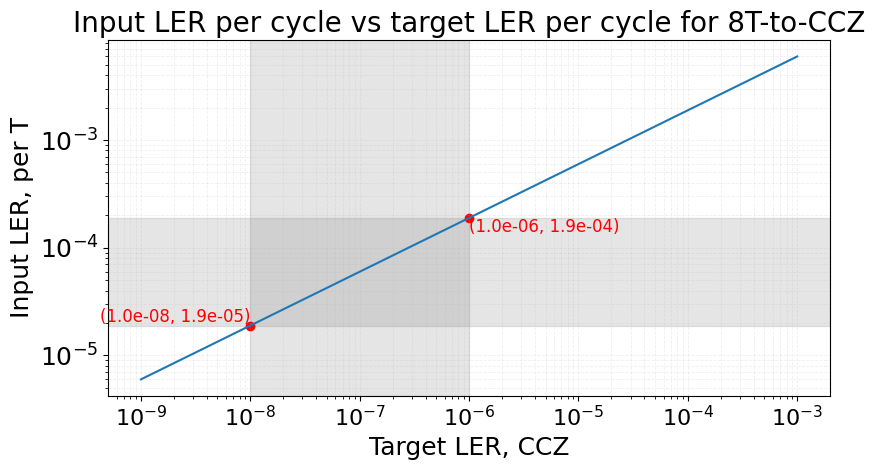

In [4]:

prot = Protocol(name="8T-to-CCZ", c=28, t=2)

p_targets = np.logspace(-9, -3, num=2000)

p_ins = [prot.p_in(_p_out) for _p_out in p_targets]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(p_targets, p_ins)

# TODO: draw a range on the plot, where

p_CCZ_intv = (1e-8, 1e-6)
p_T_intv = (prot.p_in(p_CCZ_intv[0]), prot.p_in(p_CCZ_intv[1]))

ax.axvspan(p_CCZ_intv[0], p_CCZ_intv[1], color="gray", alpha=0.2)
ax.axhspan(p_T_intv[0], p_T_intv[1], color="gray", alpha=0.2)

ax.scatter(p_CCZ_intv[0], p_T_intv[0], color="red")
ax.scatter(p_CCZ_intv[1], p_T_intv[1], color="red")
ax.text(p_CCZ_intv[0], p_T_intv[0], f"({p_CCZ_intv[0]:.1e}, {p_T_intv[0]:.1e})", color="red", ha="right", va="bottom", fontsize=12)
ax.text(p_CCZ_intv[1], p_T_intv[1], f"({p_CCZ_intv[1]:.1e}, {p_T_intv[1]:.1e})", color="red", ha="left", va="top", fontsize=12)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"Target LER, CCZ")
ax.set_ylabel(r"Input LER, per T")
ax.set_title(fr"Input LER per cycle vs target LER per cycle for {prot.name}")
ax.grid(True, which="both", linestyle="--", linewidth=0.6, alpha=0.2)
plt.tight_layout()
plt.show()



p_trgt=0.0001, d=5, n_phys=50, n_phys*8=400
p_trgt=5.0802180469130226e-05, d=5, n_phys=50, n_phys*8=400
p_trgt=2.5808615404180768e-05, d=7, n_phys=98, n_phys*8=784
p_trgt=1.311133937421563e-05, d=7, n_phys=98, n_phys*8=784
p_trgt=6.660846290809154e-06, d=7, n_phys=98, n_phys*8=784
p_trgt=3.3838551534282333e-06, d=7, n_phys=98, n_phys*8=784
p_trgt=1.7190722018585747e-06, d=9, n_phys=162, n_phys*8=1296
p_trgt=8.733261623828438e-07, d=9, n_phys=162, n_phys*8=1296
p_trgt=4.436687330978607e-07, d=9, n_phys=162, n_phys*8=1296
p_trgt=2.2539339047347934e-07, d=11, n_phys=242, n_phys*8=1936
p_trgt=1.1450475699382812e-07, d=11, n_phys=242, n_phys*8=1936
p_trgt=5.8170913293743575e-08, d=11, n_phys=242, n_phys*8=1936
p_trgt=2.955209235202888e-08, d=13, n_phys=338, n_phys*8=2704
p_trgt=1.5013107289081712e-08, d=13, n_phys=338, n_phys*8=2704
p_trgt=7.626985859023451e-09, d=13, n_phys=338, n_phys*8=2704
p_trgt=3.874675120456128e-09, d=13, n_phys=338, n_phys*8=2704
p_trgt=1.9684194472866072e-09, d=15,

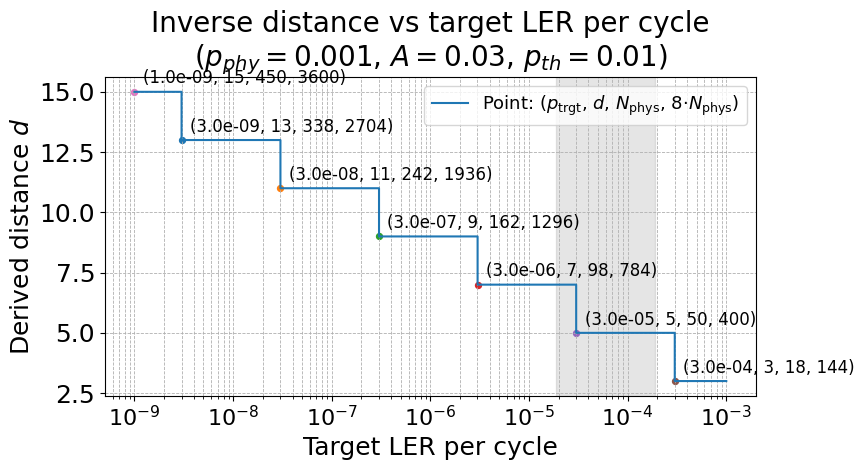

[(np.float64(3.0008108354220203e-09), 13),
 (np.float64(3.0181433966793215e-08), 11),
 (np.float64(3.0146688938996243e-07), 9),
 (np.float64(3.0111983909860628e-06), 7),
 (np.float64(3.0077318833339762e-05), 5),
 (np.float64(0.0003004269366343986), 3)]

In [ ]:

p_trgts = np.logspace(-4, -9, 18)
for p_trgt in p_trgts:
    d = surface_dist_for_trgt_p_mem(1e-3, p_trgt)
    n_phys = physical_qubits_for_surf_dist(d)
    n_T = 8
    print(f"p_trgt={p_trgt}, d={d}, n_phys={n_phys}, n_phys*{n_T}={n_phys*n_T}")


A = 0.03
p_th = 0.01
p_phy = 1e-3

# Sweep p_target from 1e-4 down to 1e-9 (we plot in increasing x for readability)
p_targets = np.logspace(-9, -3, num=2000)
ds = np.array([surface_dist_for_trgt_p_mem(p_phy, p) for p in p_targets], dtype=int)

# Find turning points where d changes
change_idx = np.where(np.diff(ds) != 0)[0] + 1
turning_points = [(p_targets[i], int(ds[i])) for i in change_idx]

# Also include endpoints for reference
# endpoints = [(p_targets[0], int(ds[0])), (p_targets[-1], int(ds[-1]))]
endpoints = [(p_targets[0], int(ds[0]))] # prevent label overlap



fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.step(p_targets, ds, where="post")
ax.set_xscale("log")
ax.set_xlabel(r"Target LER per cycle")
ax.set_ylabel(r"Derived distance $d$")
ax.set_title(f"Inverse distance vs target LER per cycle\n" + fr"($p_{{phy}}={p_phy}$, $A={A}$, $p_{{th}}={p_th}$)")
ax.grid(True, which="both", linestyle="--", linewidth=0.6)

ax.axvspan(p_T_intv[0], p_T_intv[1], color="gray", alpha=0.2)

ax.scatter(1.57 * 1e-3, 12, color="red", label="Gross MSI, per T")
# Label turning points (and endpoints)
label_points = turning_points + endpoints

# To avoid duplicate labels (endpoints might coincide with a turning point), de-duplicate by (rounded logx, y)
seen = set()
for x, y in label_points:
    key = (round(math.log10(x), 6), y)
    if key in seen:
        continue
    seen.add(key)
    plt.scatter([x], [y], s=18)
    n_phys = physical_qubits_for_surf_dist(y)
    n_T = 8
    print(f"p_trgt={x}, d={y}, n_phys={n_phys}, n_phys*{n_T}={n_phys*n_T}")
    plt.annotate(f"({x:.1e}, {y}, {n_phys}, {n_phys*n_T})", xy=(x, y),
                 xytext=(6, 6), textcoords="offset points",
                 fontsize=12)

# Add a custom legend to explain the meaning of the point labels
n_T = 8
custom_label = (
    r"Point: " +
    r"($p_{\mathrm{trgt}}$, $d$, $N_{\mathrm{phys}}$, " + f"{n_T}" + r"$\cdot N_{\mathrm{phys}}$)"
)
ax.legend([custom_label], loc='upper right', frameon=True, fontsize=13)

plt.tight_layout()
plt.show()

# Print turning points in a clean list
turning_points_sorted = sorted(turning_points, key=lambda t: t[0])  # increasing x
turning_points_sorted

